# Does hosting the Games increase a nation's medal haul, and by how much?

This notebook tells the story; the logic lives in tested modules under `src/olympic_hosts/` and in the
`.sql` files under `sql/`. It runs top to bottom from the committed raw data:
`uv run jupyter nbconvert --execute --to notebook --inplace notebooks/olympic_host_advantage.ipynb`.

**Data:** medal tables and participant lists for the 35 Summer and Winter Games from 1960 to 2026,
from Wikipedia (CC BY SA 4.0) at pinned revisions; GDP and population from the World Bank (CC BY 4.0).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from olympic_hosts import style
from olympic_hosts.build import build, panel, query
from olympic_hosts.model import (
    HEADLINE_RHS,
    estimate_alpha,
    fit,
    leave_one_host_out,
    overdispersion_test,
    prepare,
    robustness,
)
from olympic_hosts.paths import load_noc_map

warnings.filterwarnings("ignore")
style.apply()
pd.set_option("display.precision", 3)
build();

## 1. Data and the decisions behind it

The original coursework covered 1994 to 2024: 16 host events, too few to estimate an effect reliably.
This version covers 1960 to 2026: **35 host events**, 17 Summer and 18 Winter.

### Which nation is which

IOC codes change, merge and get reused. Every code maps to a *nation lineage* for a range of years in
[`data/reference/noc_map.csv`](../data/reference/noc_map.csv). The decisions that matter:

In [2]:
m = load_noc_map()
m[m["note"] != ""][["noc", "from_year", "to_year", "entity", "note"]].sort_values(["entity", "from_year"])

,noc,from_year,to_year,entity,note
1,AHO,1952,2010,AHO,"Netherlands Antilles, dissolved 2010"
2,AIN,2024,2026,AIN,Individual Neutral Athletes (Russian and Belar...
21,VOL,1972,1984,BUR,"Upper Volta, now Burkina Faso"
22,BWI,1960,1960,BWI,"British West Indies federation, 1960 only"
35,TCH,1920,1992,CZE,Czechoslovakia; counted in the Czech Republic ...
42,RAU,1960,1960,EGY,United Arab Republic
43,UAR,1960,1960,EGY,United Arab Republic (participant list code)
44,ROT,2016,2016,EOR,Refugee Olympic Team 2016; not a nation
45,EOR,2020,2100,EOR,Refugee Olympic Team; not a nation
55,GDR,1968,1988,GDR,"East Germany; its own nation, no successor"


* **Russia lineage:** Soviet Union, Unified Team (1992), Russia, OAR (2018) and ROC (2020, 2022). Sochi 2014 and
  Moscow 1980 are therefore both Russian hostings measured against one baseline.
  The Individual Neutral Athletes of 2024 and 2026 are not treated as Russia: the nation did not compete.
* **Germany lineage:** the United Team (1960, 1964), West Germany and Germany. East Germany is its own nation
  with no successor, because merging it would make reunified Germany look like a collapse.
* **Serbia lineage** for Yugoslavia, so Sarajevo 1984 has a baseline; **Czech Republic** for Czechoslovakia.
* **ROC** is Taiwan before 1980 and Russia after 2018; the year range resolves it.
* **Doping:** medal tables are taken as they stand now, after the IOC's reallocations, at the pinned revision.

### Zero means "took part and won nothing"

A nation appears in the panel only for Games it attended, taken from each Games article's list of
participants. Boycotts (1976, 1980, 1984, 1988), bans (South Africa 1964 to 1988) and nations that did not
yet exist are absent rather than zero. 2012 Summer has no list on Wikipedia; all 204 NOCs took part, so a
nation counts as present if it attended 2008 or 2016.

In [3]:
p = prepare(panel())
summary = p.groupby("season").agg(rows=("nation_id", "size"), nations=("nation_id", "nunique"),
                                  games=("games_id", "nunique"), hosts=("host", "sum"),
                                  economics_coverage=("gdp_usd", lambda s: s.notna().mean()))
summary

,rows,nations,games,hosts,economics_coverage
season,,,,,
Summer,1922,142,17,17,0.925
Winter,617,42,18,18,0.891


In [4]:
query("SELECT nation_id, games_id FROM analysis_panel WHERE (nation_id, games_id) IN "
      "(('USA', '1980S'), ('RUS', '1984S'), ('RSA', '1968S'), ('RUS', '2024S'))")

,nation_id,games_id


The query returns no rows: the USA in 1980, the Soviet Union in 1984, South Africa in 1968 and Russia in 2024
are all correctly missing.

### Medals on offer grew, so share matters as well as count

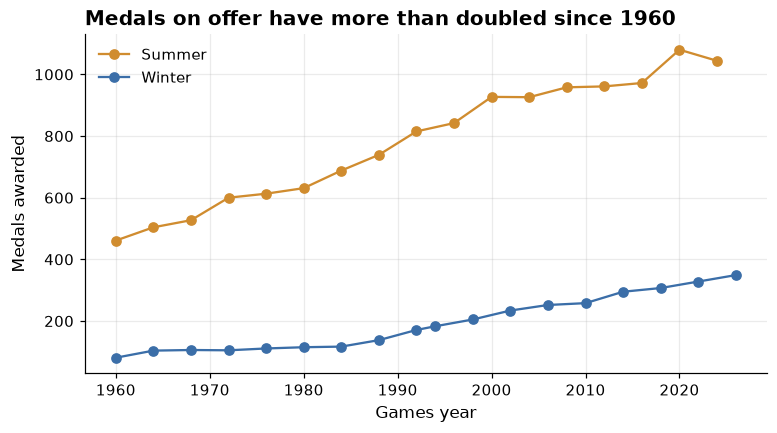

In [5]:
awarded = p.groupby(["games_id", "year", "season"], as_index=False)["medals_awarded"].first()
fig, ax = plt.subplots(figsize=(8, 4))
for season, g in awarded.groupby("season"):
    ax.plot(g["year"], g["medals_awarded"], marker="o", label=season, color=style.SEASON_COLOURS[season])
ax.set(xlabel="Games year", ylabel="Medals awarded", title="Medals on offer have more than doubled since 1960")
ax.legend()
style.save(fig, "medals_awarded");

Two consequences: raw counts cannot be compared across decades, and the models need Games fixed effects
(one dummy per Games), which absorb the number of medals on offer as well as the season.

## 2. The data model in SQL

The schema in [`sql/schema.sql`](../sql/schema.sql) replaces the original one table per Games with five
normalised tables plus the NOC mapping, and [`sql/panel.sql`](../sql/panel.sql) builds the analysis panel as
a view. The analysis queries are plain `.sql` files.

In [6]:
query("medal_share_by_nation.sql")

,season,nation_name,games,avg_share_pct,medals
0,Summer,United States,16,14.15,1705.0
1,Summer,Russia (incl. Soviet Union),15,14.00,1445.0
2,Summer,East Germany,5,12.84,409.0
3,Summer,China,11,7.11,727.0
4,Summer,Germany (incl. West Germany),16,6.24,745.0
5,Summer,Great Britain,17,4.06,569.0
6,Summer,Japan,16,3.79,470.0
7,Summer,Australia,17,3.68,511.0
8,Summer,Italy,17,3.53,454.0
9,Summer,France,17,3.31,469.0


## 3. Descriptive: each host against itself

For every hosting, the host's medal share at its home Games against its average share at every other Games
of the same season it attended.

In [7]:
hv = query("host_vs_other_years.sql")
historic = {"URS": "Soviet Union", "YUG": "Yugoslavia", "FRG": "West Germany"}
hv["label"] = hv["games_id"].str[:4] + " " + hv["host_noc"].map(historic).fillna(
    hv["host"].str.replace(r" \(incl\..*\)", "", regex=True)
)
beat = int((hv["ratio"] > 1).sum())
print(f"{beat} of {len(hv)} hosts beat their own average share; median ratio {hv['ratio'].median():.2f}")
hv.sort_values("ratio", ascending=False)

29 of 35 hosts beat their own average share; median ratio 1.76


,games_id,host_noc,host,host_share_pct,other_years_share_pct,ratio,label
13,1984W,YUG,Serbia (incl. Yugoslavia),0.85,0.16,5.50,1984 Yugoslavia
23,2004S,GRE,Greece,1.73,0.41,4.24,2004 Greece
4,1968S,MEX,Mexico,1.71,0.41,4.13,1968 Mexico
30,2018W,KOR,South Korea,5.54,1.67,3.32,2018 South Korea
16,1992S,ESP,Spain,2.70,1.09,2.48,1992 Spain
10,1980S,URS,Russia (incl. Soviet Union),30.90,12.79,2.42,1980 Soviet Union
0,1960S,ITA,Italy,7.81,3.26,2.39,1960 Italy
20,1998W,JPN,Japan,4.88,2.04,2.39,1998 Japan
5,1968W,FRA,France,8.49,3.78,2.24,1968 France
14,1988S,KOR,South Korea,4.47,2.10,2.12,1988 South Korea


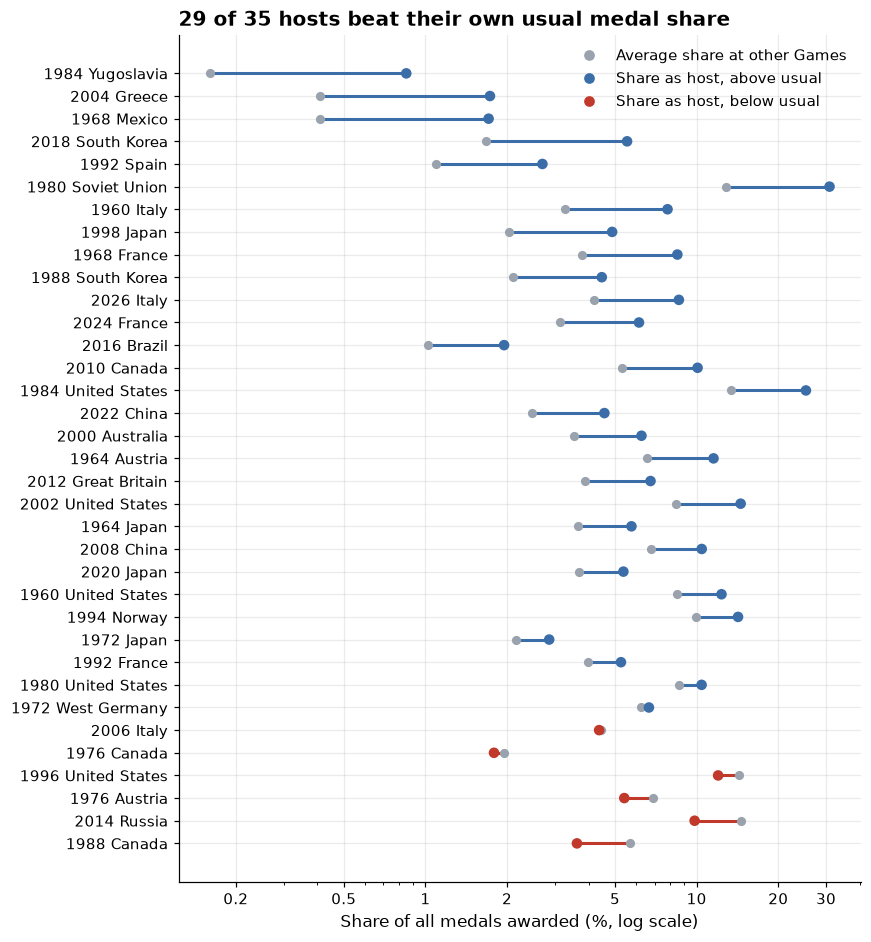

In [8]:
d = hv.sort_values("ratio")
fig, ax = plt.subplots(figsize=(8, 10))
y = np.arange(len(d))
colours = [style.ACCENT if r > 1 else style.HIGHLIGHT for r in d["ratio"]]
ax.hlines(y, d["other_years_share_pct"], d["host_share_pct"], color=colours, lw=2)
ax.scatter(d["other_years_share_pct"], y, color=style.MUTED, s=25, label="Average share at other Games", zorder=3)
ax.scatter(d["host_share_pct"], y, color=colours, s=35, label="Share as host", zorder=3)
ax.set_yticks(y, d["label"])
ax.set_xscale("log")
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10, 20, 30], ["0.2", "0.5", "1", "2", "5", "10", "20", "30"])
ax.set(xlabel="Share of all medals awarded (%, log scale)",
       title=f"{beat} of {len(hv)} hosts beat their own usual medal share")
handles = [Line2D([], [], marker="o", ls="", color=style.MUTED, label="Average share at other Games"),
           Line2D([], [], marker="o", ls="", color=style.ACCENT, label="Share as host, above usual"),
           Line2D([], [], marker="o", ls="", color=style.HIGHLIGHT, label="Share as host, below usual")]
ax.legend(handles=handles, loc="upper right")
style.save(fig, "host_vs_baseline");

### Event study: before, during and after

Each host's share at the three Games either side of hosting, as the change from its own average over the
Games three and two before hosting (before most home investment).

In [9]:
es = query("event_study.sql")
agg = es.groupby("rel")["change_pp"].agg(["mean", "sem", "count"])
agg["ci"] = 1.96 * agg["sem"]
ratio_median = (es["medal_share"] / es["base"]).groupby(es["rel"]).median()
agg.assign(median_ratio=ratio_median)

,mean,sem,count,ci,median_ratio
rel,,,,,
-3,0.164,0.275,29,0.539,0.957
-2,-0.159,0.266,30,0.521,1.039
-1,0.120,0.475,30,0.932,1.125
0,2.527,0.744,31,1.457,1.830
1,-0.022,0.626,27,1.227,1.169
2,0.209,0.781,26,1.531,1.342
3,-0.109,0.611,23,1.198,1.333


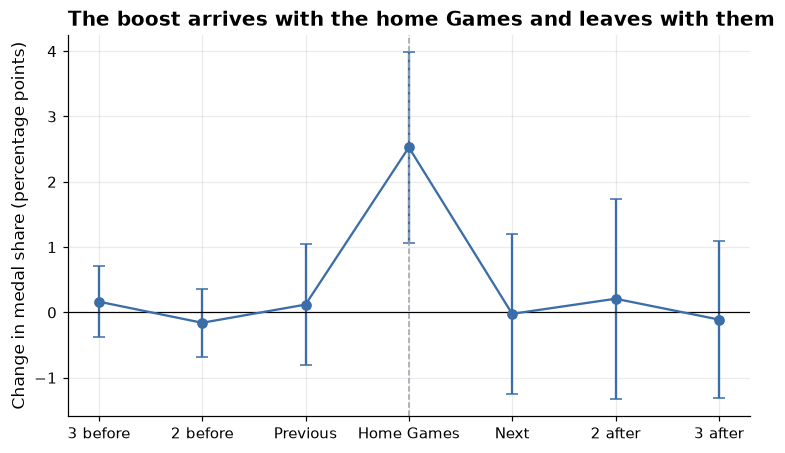

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(agg.index, agg["mean"], yerr=agg["ci"], fmt="o-", color=style.ACCENT, capsize=4)
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color=style.MUTED, ls="--", lw=1)
ax.set_xticks(agg.index, ["3 before", "2 before", "Previous", "Home Games", "Next", "2 after", "3 after"])
ax.set(ylabel="Change in medal share (percentage points)",
       title="The boost arrives with the home Games and leaves with them")
style.save(fig, "event_study");

On average there is no rise before hosting and the boost is gone by the next Games. The median host stays
somewhat above its baseline afterwards (ratio about 1.2 to 1.3), so a small legacy for typical hosts is possible;
the mean is pulled back by a few large nations. This picture is descriptive: it does not yet control for each
nation's trend or for economic growth. The model does.

## 4. Model

Outcome: medals won by a nation at a Games. Right hand side:

* **host**, the effect of interest
* **next host**: nations often invest ahead of their home Games, so a rise before hosting would bias a naive
  comparison
* **log GDP** and **log population** at the Games year (World Bank)
* **nation fixed effects**, one per nation and season, so the host effect is measured against each nation's own
  normal level rather than against other nations
* **Games fixed effects**, which absorb the medals on offer and the season

The specification was fixed before looking at results, following the project plan. Standard errors are
clustered by nation. GDP is in current US dollars: with Games fixed effects, inflation common to every nation
cancels out.

### Poisson first, then test for overdispersion

In [11]:
poisson = fit(p, HEADLINE_RHS)
print(f"{poisson.n_obs} nation Games, {poisson.n_hosts} hostings with economic data")
od = overdispersion_test(poisson)
od

2293 nation Games, 33 hostings with economic data


{'alpha': 0.05346232572584132,
 't': 13.08553292449342,
 'p_value': 8.694972918954949e-38,
 'pearson_dispersion': 1.8418660381670293}

The Cameron and Trivedi test rejects equal mean and variance (p < 0.001), and the Pearson dispersion is well
above 1. The headline model is therefore negative binomial (NB2), with the dispersion estimated by maximum
likelihood. Poisson stays as a robustness check: with clustered errors it remains consistent for the mean even
when the data are overdispersed.

In [12]:
alpha = estimate_alpha(p)
nb = fit(p, HEADLINE_RHS, alpha=alpha, name="Negative binomial")
print(f"alpha = {alpha:.3f}")
table = pd.DataFrame({t: nb.irr(t) for t in ["host", "next_host", "log_gdp", "log_pop"]}).T
table

alpha = 0.088


,irr,ci_low,ci_high,p_value
host,1.650,1.449,1.879,4.378e-14
next_host,1.080,0.950,1.229,2.384e-01
log_gdp,1.246,1.025,1.516,2.741e-02
log_pop,2.932,1.669,5.150,1.825e-04


In [13]:
h = nb.irr()
print(f"Hosts win {h.irr - 1:.0%} more medals than their own baseline "
      f"(IRR {h.irr:.2f}, 95% CI {h.ci_low:.2f} to {h.ci_high:.2f}).")
n = nb.irr("next_host")
print(f"Next host: IRR {n.irr:.2f} (95% CI {n.ci_low:.2f} to {n.ci_high:.2f}), no measurable rise before hosting.")

Hosts win 65% more medals than their own baseline (IRR 1.65, 95% CI 1.45 to 1.88).
Next host: IRR 1.08 (95% CI 0.95 to 1.23), no measurable rise before hosting.


### Summer against Winter

In [14]:
inter = fit(p, HEADLINE_RHS.replace("host +", "host + host_winter +"), alpha=alpha)
pd.DataFrame({
    "Summer": inter.irr("host"),
    "Winter": inter.combined_irr(["host", "host_winter"]),
    "Winter / Summer": inter.irr("host_winter"),
}).T

,irr,ci_low,ci_high,p_value
Summer,1.793,1.457,2.207,3.647e-08
Winter,1.475,1.301,1.673,1.434e-09
Winter / Summer,0.823,0.636,1.064,1.377e-01


Summer hosts gain somewhat more than Winter hosts (about 79% against 47%), but the difference between them is not statistically clear (p = 0.14), so the pooled estimate is the headline.

## 5. Robustness

In [15]:
rob = robustness(p, alpha)
rob

,n_obs,hosts,irr,ci_low,ci_high,p_value
specification,,,,,,
Headline: negative binomial,2293,33,1.650,1.449,1.879,4.378e-14
Poisson instead of negative binomial,2293,33,1.538,1.355,1.746,3.008e-11
No GDP or population (all 35 hosts),2539,35,1.669,1.457,1.911,1.275e-13
Boycott Games 1976 to 1984 dropped,2059,31,1.648,1.444,1.881,1.237e-13
Medal share instead of count,2293,33,1.511,1.353,1.688,2.262e-13
Summer Games only,1761,16,1.796,1.455,2.217,5.185e-08
Winter Games only,532,17,1.473,1.285,1.688,2.502e-08


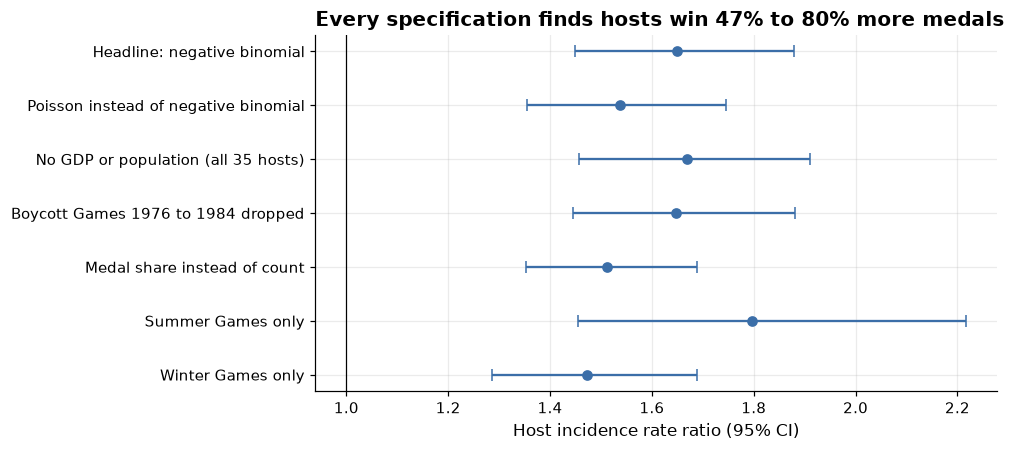

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
d = rob.iloc[::-1]
y = np.arange(len(d))
ax.errorbar(d["irr"], y, xerr=[d["irr"] - d["ci_low"], d["ci_high"] - d["irr"]], fmt="o",
            color=style.ACCENT, capsize=4)
ax.axvline(1, color="black", lw=0.8)
ax.set_yticks(y, d.index)
lo, hi = rob["irr"].min(), rob["irr"].max()
ax.set(xlabel="Host incidence rate ratio (95% CI)",
       title=f"Every specification finds hosts win {lo - 1:.0%} to {hi - 1:.0%} more medals")
style.save(fig, "robustness");

In [17]:
loho = leave_one_host_out(p, alpha)
print(f"Leave one host out: IRR ranges from {loho['irr'].min():.2f} to {loho['irr'].max():.2f}")
loho.sort_values("irr").iloc[[0, 1, -2, -1]]

Leave one host out: IRR ranges from 1.60 to 1.69


,dropped,nation,irr,ci_low,ci_high,p_value
13,1968S,Mexico,1.604,1.428,1.801,1.414e-15
8,2004S,Greece,1.613,1.430,1.821,8.773e-15
29,2014W,Russia (incl. Soviet Union),1.684,1.480,1.916,2.670e-15
15,1996S,United States,1.691,1.494,1.913,8.678e-17


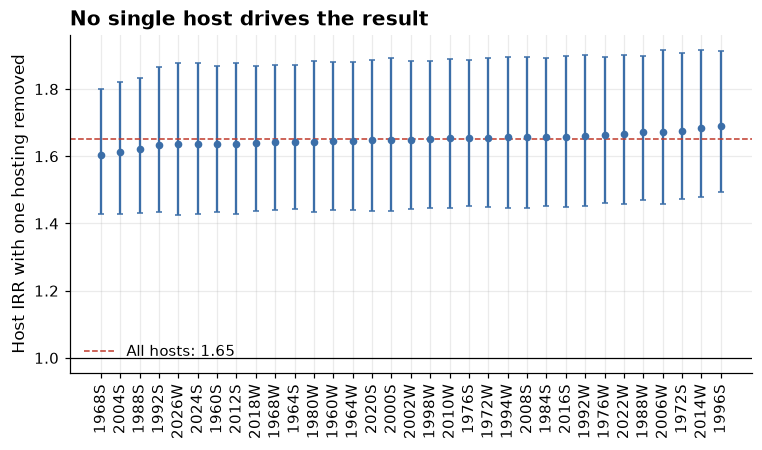

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
d = loho.sort_values("irr").reset_index(drop=True)
ax.errorbar(d.index, d["irr"], yerr=[d["irr"] - d["ci_low"], d["ci_high"] - d["irr"]], fmt="o",
            color=style.ACCENT, capsize=2, ms=4)
ax.axhline(h.irr, color=style.HIGHLIGHT, ls="--", lw=1, label=f"All hosts: {h.irr:.2f}")
ax.axhline(1, color="black", lw=0.8)
ax.set_xticks(d.index, d["dropped"], rotation=90)
ax.set(ylabel="Host IRR with one hosting removed",
       title="No single host drives the result")
ax.legend()
style.save(fig, "leave_one_out");

## Summary

* Hosts win about **65% more medals** than their own baseline (negative binomial IRR 1.65, 95% CI 1.45 to 1.88),
  controlling for GDP, population, the medals on offer and each nation's normal level.
* There is no measurable rise at the Games before hosting, and on average the boost is gone by the Games after.
* The result holds with Poisson, without economic controls, without the boycott Games, as a medal share, in each
  season separately, and with any single host removed.

## Limitations

* **Selection into hosting.** Nations that bid are rich and already sporting. Nation fixed effects remove their
  usual level, and next host and GDP controls cover investment and growth, but a nation that wins the bid may
  also be on an upward path for reasons the model cannot see.
* **35 host events.** Enough for a clear average effect, not for explaining which hosts gain most.
* **Missing economics.** The World Bank has no data for the Soviet Union or Yugoslavia, so Moscow 1980 and
  Sarajevo 1984 drop out of the headline model; the specification without GDP and population keeps all 35.
* **Correlation, not proof of cause.** The design compares each nation with itself, which rules out most
  obvious confounders, but it is not an experiment. Mechanisms (crowd support, familiarity, automatic entry
  places, extra events chosen by the host, judging) cannot be separated with medal counts alone.